# Multi-Scale HMM 01 — momentum / reversal states on 1h, 4h and 1D bars

Pre-registration: `discussions/Multi_Scale_HMM/001_claude_branch_preregistration.md`. Everything that decides the result is fixed in
`src/data_engineering/modeling/multiscale_hmm.py` (`registration()` below).

- **Bars:** UTC-aligned 1h / 4h / 1D bars built from Binance USD-M perpetual 1-minute klines; each bar carries intrabar emissions
  (standardized return, relative and absolute volatility, semivariance asymmetry, signed efficiency, close location, wick share,
  bipower jump share, signed taker flow, relative activity).
- **Model:** pooled multivariate Student-t HMM; $K$ and $\nu$ chosen on VALID; refitted on TRAIN+VALID and frozen.
- **Forecast:** per-state $y_{t+1}=a_k+b_k z_t$ ($b_k>0$ momentum, $b_k<0$ reversal), weighted by the filtered state probabilities.
- **Verdicts per scale:** S (statistical, sign-flip null with full refit, $\alpha=0.05/3$), E (net of 6 bp/side and funding, day-block
  bootstrap), states-add-value (vs $K=1$), and later P (prospective, data after 2026-10-18).

Environment: `MSH01_SCALES` (default `1h,4h,1D`), `MSH01_JOBS` (null worker processes, default CPU count − 1),
`MSH01_N_NULL` (override for a quick look only — the decision uses the registered counts), `MSH01_SYNTHETIC=1` (smoke run to a temp dir).

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC = str(PROJECT_ROOT / 'src')
sys.path.insert(0, SRC)
os.environ['PYTHONPATH'] = SRC + (os.pathsep + os.environ['PYTHONPATH'] if os.environ.get('PYTHONPATH') else '')  # for null workers
from data_engineering.modeling import multiscale_hmm as mh

SYNTHETIC = os.getenv('MSH01_SYNTHETIC', '').strip() == '1'
SCALES = [s.strip() for s in os.getenv('MSH01_SCALES', '1h,4h,1D').split(',') if s.strip()]
JOBS = int(os.getenv('MSH01_JOBS', str(max(1, (os.cpu_count() or 2) - 1))))
N_NULL = {s: int(os.getenv('MSH01_N_NULL', str(mh.N_NULL[s]))) for s in SCALES}
SPEC = mh.Spec(restarts=2 if SYNTHETIC else mh.RESTARTS, null_restarts=2 if SYNTHETIC else mh.NULL_RESTARTS)
if SYNTHETIC:
    N_NULL = {s: min(N_NULL[s], 4) for s in SCALES}
    OUT = Path(tempfile.mkdtemp(prefix='msh01_'))
else:
    DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or DATA_ROOT.parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Multi_Scale_HMM' / '01'
OUT.mkdir(parents=True, exist_ok=True)
REGISTERED_RUN = (not SYNTHETIC) and all(N_NULL[s] == mh.N_NULL[s] for s in SCALES)
print(mh.selftest())
print('scales', SCALES, '| null', N_NULL, '| jobs', JOBS, '| registered run' if REGISTERED_RUN else '| NOT the registered run', '| out', OUT)
print(json.dumps(mh.registration(SPEC), indent=1, default=mh.json_default))

multiscale_hmm 1.0.0: forward-backward selftest ok (err 2.2e-16)
scales ['1h', '4h', '1D'] | null {'1h': 99, '4h': 199, '1D': 199} | jobs 3 | registered run | out D:\Projects\deribit_market_data\notebooks\Multi_Scale_HMM\01
{
 "version": "multiscale_hmm 1.0.0",
 "assets": [
  "BTC",
  "ETH",
  "SOL",
  "XRP"
 ],
 "scales_min": {
  "1h": 60,
  "4h": 240,
  "1D": 1440
 },
 "features": [
  "z",
  "lrv",
  "lsig",
  "semi",
  "er",
  "clv",
  "wick",
  "jump",
  "flow",
  "lvol"
 ],
 "halflife_bars": {
  "1h": 24,
  "4h": 18,
  "1D": 10
 },
 "k_grid": {
  "1h": [
   1,
   2,
   3,
   4,
   5,
   6
  ],
  "4h": [
   1,
   2,
   3,
   4,
   5,
   6
  ],
  "1D": [
   1,
   2,
   3,
   4
  ]
 },
 "nu_grid": [
  4.0,
  7.0,
  15.0,
  50.0
 ],
 "train": [
  "2024-10-01 00:00:00+00:00",
  "2025-09-01 00:00:00+00:00"
 ],
 "valid": [
  "2025-09-01 00:00:00+00:00",
  "2026-02-01 00:00:00+00:00"
 ],
 "test": [
  "2026-02-01 00:00:00+00:00",
  "2026-10-18 00:00:00+00:00"
 ],
 "prospective_from": "2026

## 1. Data: 1-minute perpetual klines and funding (truncated at the end of TEST; later data is the prospective window)

In [2]:
MIN, FUND, cov = {}, {}, []
if SYNTHETIC:
    MIN = mh.synthetic_minutes(760, seed=1, planted=0.3)
    FUND = mh.synthetic_funding(MIN)
else:
    for a in SPEC.assets:
        p = BIN_DIR / f'{a}USDT_um_1m.parquet'
        if not p.exists():
            raise FileNotFoundError(f'{p} missing: run tools\\download_binance_um_klines.py')
        MIN[a] = mh.load_um_1m(p)
        fp = BIN_DIR / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        FUND[a] = mh.load_funding(fp) if fp.exists() else None
        if FUND[a] is None:
            print(f'WARNING {a}: no funding file at {fp} -> E cannot pass (tools\\download_binance_basis_data.py)')
for a in list(MIN):
    m = MIN[a]
    MIN[a] = m[m['open_time'] < mh.TEST_END - pd.Timedelta(minutes=1) + pd.Timedelta(seconds=1)].reset_index(drop=True)
    f = FUND.get(a)
    cov.append({'asset': a, 'first_minute': MIN[a]['open_time'].min(), 'last_minute': MIN[a]['open_time'].max(),
                'minutes': len(MIN[a]), 'funding_rows': 0 if f is None else int((f.index < mh.TEST_END).sum()),
                'funding_last': None if f is None else f.index.max()})
cov = pd.DataFrame(cov); cov.to_csv(OUT / '01_coverage.csv', index=False); display(cov)
assert (cov['first_minute'] <= mh.TRAIN_START + pd.Timedelta(days=15)).all(), 'data must start by mid-Oct 2024 (warm-up)'

,asset,first_minute,last_minute,minutes,funding_rows,funding_last
0,BTC,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,2373,2026-09-30 16:00:00.002000+00:00
1,ETH,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,2373,2026-09-30 16:00:00.002000+00:00
2,SOL,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,2373,2026-09-30 16:00:00.002000+00:00
3,XRP,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,2373,2026-09-30 16:00:00.002000+00:00


## 2. Model selection on VALID ($K$, $\nu$), then frozen fit on TRAIN+VALID and the TEST forecasts

In [3]:
PANELS, SEL, RES, STATES, ASSET_ROWS = {}, [], {}, [], []
for sc in SCALES:
    t0 = time.time()
    P = mh.build_panel(MIN, sc, FUND)
    PANELS[sc] = P
    sel = mh.select_model(P, sc, SPEC.restarts, SPEC.seed)
    SEL.append(sel)
    best = sel.sort_values('valid_ll_per_bar', ascending=False).iloc[0]
    K, nu = int(best['K']), float(best['nu'])
    r = mh.run_pipeline(P, sc, K, nu, SPEC.restarts, SPEC.seed)
    RES[sc] = r
    STATES.append(mh.state_table(r, P, sc))
    for a, v in r['per_asset'].items():
        ASSET_ROWS.append({'scale': sc, 'asset': a, **v})
    (OUT / f'01_frozen_model_{sc}.json').write_text(json.dumps({
        'scale': sc, 'model': r['model'].to_dict(), 'regression': r['reg'].to_dict('records'),
        'regression_k1': r['reg_k1'].to_dict('records'), 'standardization': r['stats'], 'version': mh.VERSION},
        indent=1, default=mh.json_default))
    print(f"{sc}: K={K} nu={nu}  S={r['S_stat_bp']:.3f} bp/bar ({r['S_assets_positive']}/4 assets >0)  "
          f"net {r['net_mean_bp_day']:.1f} bp/day [{r['net_lo_bp_day']:.1f}, {r['net_hi_bp_day']:.1f}]  {time.time()-t0:.0f}s")
SEL = pd.concat(SEL); SEL.to_csv(OUT / '01_selection.csv', index=False)
STATES = pd.concat(STATES); STATES.to_csv(OUT / '01_states.csv', index=False)
ASSET_ROWS = pd.DataFrame(ASSET_ROWS); ASSET_ROWS.to_csv(OUT / '01_per_asset.csv', index=False)
display(SEL.round(4)); display(STATES.round(3)); display(ASSET_ROWS.round(3))

1h: K=6 nu=15.0  S=-0.051 bp/bar (2/4 assets >0)  net -0.6 bp/day [-3.3, 1.3]  526s
4h: K=6 nu=15.0  S=0.625 bp/bar (3/4 assets >0)  net 2.6 bp/day [-1.7, 7.3]  72s
1D: K=4 nu=7.0  S=-20.859 bp/bar (1/4 assets >0)  net -13.6 bp/day [-34.7, 7.4]  7s


,scale,K,nu,train_ll_per_bar,valid_ll_per_bar,n_train,n_valid,bic_train
0,1h,1,4.0,-10.4467,-11.0380,31872,14688,666588.0152
1,1h,1,7.0,-10.3786,-10.9852,31872,14688,662244.8496
2,1h,1,15.0,-10.3837,-11.0185,31872,14688,662575.1229
3,1h,1,50.0,-10.5033,-11.1880,31872,14688,670194.2530
4,1h,2,4.0,-8.9708,-9.6084,31872,14688,573211.4099
...,...,...,...,...,...,...,...,...
11,1D,3,50.0,-8.3123,-10.5650,1220,612,21724.6915
12,1D,4,4.0,-7.8343,-9.6352,1220,612,21070.0447
13,1D,4,7.0,-7.7454,-9.6255,1220,612,20853.0293
14,1D,4,15.0,-7.7091,-9.7302,1220,612,20764.5129


,scale,state,occupancy,exp_duration_bars,exp_duration_hours,mean_z,mean_lrv,mean_lsig,mean_semi,mean_er,mean_clv,mean_wick,mean_jump,mean_flow,mean_lvol,a,se_a,b,se_b,label
0,1h,0,0.054,16.622,16.622,0.038,-1.144,-4.206,0.014,0.007,0.021,0.591,0.057,-0.013,-0.642,-0.000,0.013,-0.050,0.029,no-autocorr
1,1h,1,0.311,1.562,1.562,0.361,-0.618,-5.043,0.118,0.083,0.348,0.656,0.080,0.022,-0.448,-0.007,0.012,0.011,0.028,no-autocorr
2,1h,2,0.153,1.399,1.399,-0.352,0.081,-5.012,-0.076,-0.056,-0.215,0.763,0.064,-0.036,0.054,0.002,0.018,-0.051,0.040,no-autocorr
3,1h,3,0.198,1.646,1.646,-0.364,-1.031,-5.068,-0.147,-0.099,-0.356,0.599,0.096,-0.064,-0.729,-0.021,0.011,-0.001,0.026,no-autocorr
4,1h,4,0.154,1.250,1.250,1.407,0.068,-5.022,0.319,0.221,0.629,0.320,0.084,0.068,0.182,-0.035,0.035,0.037,0.025,no-autocorr
5,1h,5,0.130,1.226,1.226,-1.579,0.231,-5.013,-0.320,-0.226,-0.621,0.308,0.077,-0.096,0.314,0.029,0.037,0.019,0.025,no-autocorr
0,4h,0,0.193,1.258,5.031,-0.160,-0.551,-4.303,-0.028,-0.017,-0.113,0.843,0.059,-0.025,-0.360,0.009,0.026,0.017,0.135,no-autocorr
1,4h,1,0.191,1.261,5.046,-0.625,-0.504,-4.321,-0.117,-0.068,-0.474,0.485,0.063,-0.047,-0.285,0.004,0.041,0.081,0.067,no-autocorr
2,4h,2,0.168,1.267,5.067,1.357,0.047,-4.296,0.187,0.112,0.630,0.332,0.058,0.029,0.180,0.003,0.049,0.026,0.035,no-autocorr
3,4h,3,0.288,1.477,5.906,0.338,-0.595,-4.305,0.065,0.039,0.341,0.672,0.061,0.003,-0.394,0.012,0.026,0.053,0.069,no-autocorr


,scale,asset,n_test,gross_bp_per_bar,hit_rate,r2_os,net_total_pct,net_trades,k1_gross_bp_per_bar,k1_net_total_pct,tsmom_gross_bp_per_bar
0,1h,BTC,6071,0.342,0.515,-0.000,-0.266,2.0,0.030,-0.266,0.849
1,1h,ETH,6071,-0.289,0.499,0.001,3.918,17.0,0.334,0.042,0.701
2,1h,SOL,6071,0.525,0.495,-0.001,0.407,8.0,-0.363,0.000,0.858
3,1h,XRP,6071,-0.781,0.488,-0.002,-10.477,23.0,0.683,-3.419,0.901
4,4h,BTC,1517,0.566,0.483,-0.000,-1.065,6.0,-0.653,-0.305,-1.411
5,4h,ETH,1517,-1.951,0.469,-0.002,12.344,72.0,-0.522,-5.787,-0.237
6,4h,SOL,1517,2.879,0.479,0.001,1.499,98.0,2.406,-0.681,1.692
7,4h,XRP,1517,1.008,0.470,-0.000,13.531,90.0,3.936,23.046,-1.148
8,1D,BTC,252,-20.264,0.452,-0.018,-26.027,160.0,18.982,14.464,4.440
9,1D,ETH,252,-31.455,0.464,-0.022,-56.159,172.0,10.842,6.884,7.759


## 3. Sign-flip null (full refit per draw, $K$ and $\nu$ fixed at the real-data choice)

In [4]:
NULLS = {}
for sc in SCALES:
    t0 = time.time(); r = RES[sc]
    def prog(i, n, sc=sc, t0=t0):
        if i % 10 == 0 or i == n:
            print(f'  {sc} null {i}/{n}  {time.time()-t0:.0f}s', flush=True)
    NULLS[sc] = mh.run_null(MIN, sc, r['K'], r['nu'], N_NULL[sc], SPEC.null_restarts, SPEC.seed, JOBS, prog)
    NULLS[sc].assign(scale=sc).to_csv(OUT / f'01_null_{sc}.csv', index=False)

  1h null 10/99  241s
  1h null 20/99  483s
  1h null 30/99  689s
  1h null 40/99  905s
  1h null 50/99  1155s
  1h null 60/99  1752s
  1h null 70/99  2659s
  1h null 80/99  3497s
  1h null 90/99  4219s
  1h null 99/99  4434s
  4h null 10/199  89s
  4h null 20/199  140s
  4h null 30/199  209s
  4h null 40/199  258s
  4h null 50/199  309s
  4h null 60/199  363s
  4h null 70/199  413s
  4h null 80/199  471s
  4h null 90/199  523s
  4h null 100/199  576s
  4h null 110/199  636s
  4h null 120/199  684s
  4h null 130/199  735s
  4h null 140/199  792s
  4h null 150/199  844s
  4h null 160/199  892s
  4h null 170/199  954s
  4h null 180/199  1006s
  4h null 190/199  1052s
  4h null 199/199  1100s
  1D null 10/199  40s
  1D null 20/199  71s
  1D null 30/199  101s
  1D null 40/199  136s
  1D null 50/199  167s
  1D null 60/199  197s
  1D null 70/199  232s
  1D null 80/199  263s
  1D null 90/199  293s
  1D null 100/199  328s
  1D null 110/199  359s
  1D null 120/199  389s
  1D null 130/199  424s


## 4. Verdicts

In [5]:
rows = []
for sc in SCALES:
    r, v = RES[sc], mh.verdict(RES[sc], NULLS[sc])
    rows.append({'scale': sc, 'K': r['K'], 'nu': r['nu'], 'S_stat_bp_per_bar': r['S_stat_bp'],
                 'S_assets_positive': r['S_assets_positive'], 'k1_S_stat_bp': r['k1_S_stat_bp'],
                 'tsmom_S_stat_bp': r['tsmom_S_stat_bp'], 'drift_S_stat_bp': r['drift_S_stat_bp'],
                 'net_mean_bp_day': r['net_mean_bp_day'], 'net_lo_bp_day': r['net_lo_bp_day'],
                 'net_hi_bp_day': r['net_hi_bp_day'], 'cost_bp_day': r['net_cost_bp_day'],
                 'funding_bp_day': r['net_funding_bp_day'], 'E_assets_positive': r['E_assets_positive'],
                 'k1_net_mean_bp_day': r['k1_net_mean_bp_day'], 'incr_mean_bp_day': r['incr_mean_bp_day'],
                 'incr_lo_bp_day': r['incr_lo_bp_day'], 'funding_missing': r['funding_missing'], **v})
SUM = pd.DataFrame(rows); SUM.to_csv(OUT / '01_summary.csv', index=False); display(SUM.T)
decision = {'version': mh.VERSION, 'registered_run': REGISTERED_RUN, 'synthetic': SYNTHETIC,
            'per_scale': {r['scale']: {k: r[k] for k in ('S_verdict', 'S_p', 'E_verdict', 'states_add_value', 'scale_verdict')} for r in rows},
            'branch_verdict': ('CANDIDATES: ' + ','.join(r['scale'] for r in rows if r['scale_verdict'] == 'CANDIDATE_FOR_PROSPECTIVE'))
                              if any(r['scale_verdict'] == 'CANDIDATE_FOR_PROSPECTIVE' for r in rows) else 'NO_TRADEABLE_MOMENTUM_STATES'}
(OUT / '01_decision.json').write_text(json.dumps(decision, indent=1, default=mh.json_default))
(OUT / '01_manifest.json').write_text(json.dumps({'registration': mh.registration(SPEC), 'n_null_used': N_NULL,
                                                  'jobs': JOBS, 'coverage': cov.to_dict('records')}, indent=1, default=mh.json_default))
print(json.dumps(decision, indent=1, default=mh.json_default))

,0,1,2
scale,1h,4h,1D
K,6,6,4
nu,15.0,15.0,7.0
S_stat_bp_per_bar,-0.050984,0.625146,-20.859093
S_assets_positive,2,3,1
k1_S_stat_bp,0.171206,1.291883,18.469029
tsmom_S_stat_bp,0.827232,-0.275989,5.044511
drift_S_stat_bp,0.023102,0.071406,-2.895054
net_mean_bp_day,-0.634083,2.599733,-13.561691
net_lo_bp_day,-3.314926,-1.655766,-34.672558


{
 "version": "multiscale_hmm 1.0.0",
 "registered_run": true,
 "synthetic": false,
 "per_scale": {
  "1h": {
   "S_verdict": "NO_SKILL",
   "S_p": 0.57,
   "E_verdict": "NO_NET_EDGE",
   "states_add_value": false,
   "scale_verdict": "NO_TRADEABLE_MOMENTUM_STATES"
  },
  "4h": {
   "S_verdict": "NO_SKILL",
   "S_p": 0.46,
   "E_verdict": "NO_NET_EDGE",
   "states_add_value": false,
   "scale_verdict": "NO_TRADEABLE_MOMENTUM_STATES"
  },
  "1D": {
   "S_verdict": "NO_SKILL",
   "S_p": 0.925,
   "E_verdict": "NO_NET_EDGE",
   "states_add_value": false,
   "scale_verdict": "NO_TRADEABLE_MOMENTUM_STATES"
  }
 },
 "branch_verdict": "NO_TRADEABLE_MOMENTUM_STATES"
}


## 5. TEST equity curves (net rule, equal weight; HMM vs $K=1$) and null distributions

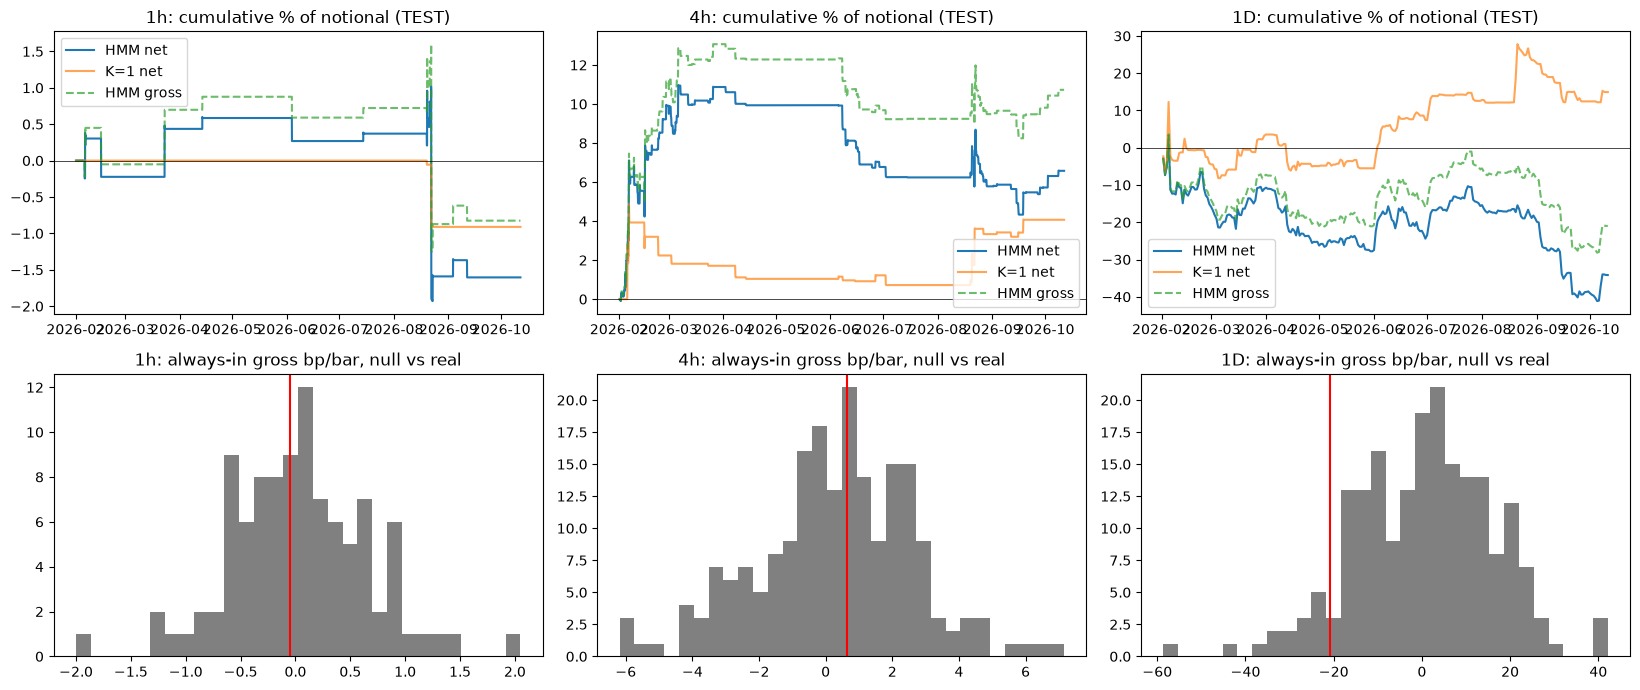

In [6]:
fig, ax = plt.subplots(2, len(SCALES), figsize=(5.5 * len(SCALES), 7), squeeze=False)
for j, sc in enumerate(SCALES):
    r = RES[sc]
    pn = mh.portfolio(r['net_rule']); pb = mh.portfolio({a: mh.pnl_frame(r['detail'][a].assign(
        fund_next=PANELS[sc][a]['fund_next'], seg=PANELS[sc][a]['seg']), r['detail'][a]['mhat_k1'].to_numpy(),
        (mh.window_mask(PANELS[sc][a], mh.TEST_START, mh.TEST_END) & np.isfinite(PANELS[sc][a]['r_next'].to_numpy(float))))
        for a in r['detail']})
    ax[0, j].plot(pd.to_datetime(pn['bar_end']), 100 * pn['net'].cumsum(), label='HMM net')
    ax[0, j].plot(pd.to_datetime(pb['bar_end']), 100 * pb['net'].cumsum(), label='K=1 net', alpha=.7)
    ax[0, j].plot(pd.to_datetime(pn['bar_end']), 100 * pn['gross'].cumsum(), label='HMM gross', ls='--', alpha=.7)
    ax[0, j].set_title(f'{sc}: cumulative % of notional (TEST)'); ax[0, j].legend(); ax[0, j].axhline(0, c='k', lw=.5)
    ax[1, j].hist(NULLS[sc]['S_stat_bp'], bins=30, color='grey'); ax[1, j].axvline(r['S_stat_bp'], c='r')
    ax[1, j].set_title(f'{sc}: always-in gross bp/bar, null vs real')
plt.tight_layout(); plt.savefig(OUT / '01_equity_and_null.png', dpi=110); plt.show()